# Fig. 4(b): 保留 KV 与缩减 KV 的 100% 堆叠横柱图

每条横柱对应 refinement 前的 100% Loaded KV。左侧实心条纹段表示保留比例（100% − reduction），右侧同色半透明无条纹段表示缩减比例；缩减比例标注在半透明段中央。

本 notebook 独立运行，直接读取同目录 `ressum.md` 中的 Passkey 数据。运行全部单元会更新本目录和论文 Figures 目录中的同名 PDF，以及 PNG 预览。figure 画布保持 6.0 × 2.75 英寸。


In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.colors import to_rgba
from matplotlib.patches import Patch
from IPython.display import display

PROJECT = next(
    (p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
     if (p / "Paper/DAC2027/Figures/source/build_experiment_figures.py").is_file()),
    None,
)
if PROJECT is None:
    raise FileNotFoundError("请从 SparseAttention 项目内启动 notebook，或手动设置 PROJECT。")

FIGURES = PROJECT / "Paper/DAC2027/Figures"
PREVIEW = PROJECT / "Paper/DAC2027/build/experiment-figures"
PLOT_DIR = PROJECT / "会用到的论文图与复现/fig4b-Passkey-KV减少"
DATA_SOURCE = PLOT_DIR / "ressum.md"
OUTPUT_NAME = "experiment_kv_retained_reduced"

for name in ("Times New Roman.ttf", "Times New Roman Bold.ttf"):
    font_path = Path("/System/Library/Fonts/Supplemental") / name
    if font_path.exists():
        font_manager.fontManager.addfont(str(font_path))

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "STIXGeneral", "DejaVu Serif"],
    "font.size": 9,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "axes.linewidth": 0.6,
    "hatch.linewidth": 0.7,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "savefig.facecolor": "white",
})


## 数据来源

读取同目录 `ressum.md` 的全部八组 Passkey 结果，顺序与表格一致：LLaMA-3.1 / Qwen3-8B × Quest / DS × 8K / 16K，Accuracy 均为 100%。图中模型简称分别为 LLaMA 和 Qwen3。

`REDUCTION_PCT` 使用表中保留两位小数的 Reduction，并核对其与 `100 × (1 − After KV / Before KV)` 一致。每行以自身的 Before KV 为 100%，保留比例为 `100 − Reduction`；两段总和始终为 100%。修改 `ressum.md` 后重新运行即可更新数据。


In [2]:
table_rows = [
    [value.strip() for value in line.strip().strip("|").split("|")]
    for line in DATA_SOURCE.read_text(encoding="utf-8").splitlines()
    if line.strip().startswith("|")
]
data_rows = table_rows[2:]  # 跳过 Markdown 表头和分隔行。
MODEL_LABELS = {"LLaMA-3.1": "LLaMA", "Qwen3-8B": "Qwen3"}

BAR_LABELS = [
    f"{MODEL_LABELS[model]}/{selector} {length}"
    for model, selector, length, *_ in data_rows
]
GROUP_KEYS = [(MODEL_LABELS[row[0]], row[1]) for row in data_rows]
BEFORE_KV = np.array([float(row[3]) for row in data_rows])
AFTER_KV = np.array([float(row[4]) for row in data_rows])
REDUCTION_PCT = np.array([float(row[5].rstrip("%")) for row in data_rows])
ACCURACY_PCT = np.array([float(row[6].rstrip("%")) for row in data_rows])

if not np.all((BEFORE_KV > 0) & (AFTER_KV >= 0) & (AFTER_KV <= BEFORE_KV)):
    raise ValueError("Before/After KV 必须满足 0 <= After <= Before 且 Before > 0。")
if not np.allclose(REDUCTION_PCT, 100 * (1 - AFTER_KV / BEFORE_KV), atol=0.005, rtol=0):
    raise ValueError("ressum.md 的 Reduction 与 Before/After KV 不一致。")


## 可编辑的样式

原有三个模型/selector 组合沿用原配色，新增 Qwen3/DS 使用紫色；保留段均加条纹。`REDUCTION_ALPHA` 控制缩减段的透明度：0 为完全透明，1 为完全不透明。坐标轴表示相对于 refinement 前 Loaded KV 的百分比。

`FIGSIZE = (6.0, 2.75)` 保持不变；导出时不裁切画布，PDF 为 6.0 × 2.75 英寸，300 dpi PNG 为 1800 × 825 像素。


In [3]:
INK = "#243136"
PASSKEY_STYLES = {
    ("LLaMA", "Quest"): ("#8DB67A", "////"),
    ("Qwen3", "Quest"): ("#7EC0EE", "////"),
    ("LLaMA", "DS"): ("#F2C867", "////"),
    ("Qwen3", "DS"): ("#B7A3D5", "////"),
}

FIGSIZE = (6.0, 2.75)
BAR_HEIGHT = 0.63
REDUCTION_ALPHA = 0.25
PERCENT_FONT_SIZE = 9.5
TICK_FONT_SIZE = 9
AXIS_LABEL_SIZE = 10


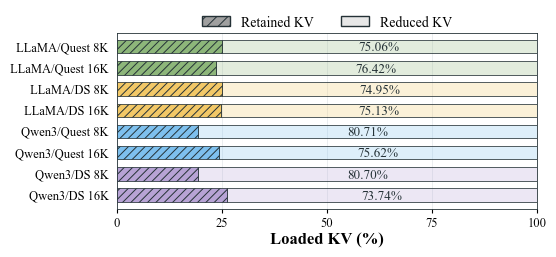

In [4]:
def plot_passkey_retained_reduced(labels, group_keys, reduction_pct):
    reduction = np.asarray(reduction_pct, dtype=float)
    if reduction.shape != (len(labels),) or len(group_keys) != len(labels):
        raise ValueError("标签、方法组合和 reduction 数组长度必须一致。")
    if not np.all(np.isfinite(reduction) & (reduction >= 0) & (reduction <= 100)):
        raise ValueError("reduction 必须是 0 到 100 之间的有限数值。")

    retained = 100.0 - reduction
    positions = np.arange(len(labels))[::-1]
    fig, ax = plt.subplots(figsize=FIGSIZE)
    fig.subplots_adjust(left=0.27, right=0.97, bottom=0.20, top=0.84)
    ax.set_axisbelow(True)
    ax.grid(axis="x", color="#dce2e5", linewidth=0.5, alpha=0.8)

    for i, (position, key) in enumerate(zip(positions, group_keys)):
        color, hatch = PASSKEY_STYLES[key]
        ax.barh(
            position, retained[i], height=BAR_HEIGHT,
            color=color, edgecolor=INK, linewidth=0.55,
            hatch=hatch, zorder=3,
        )
        ax.barh(
            position, reduction[i], left=retained[i], height=BAR_HEIGHT,
            facecolor=to_rgba(color, REDUCTION_ALPHA),
            edgecolor=INK, linewidth=0.55, hatch=None, zorder=2,
        )
        ax.text(
            retained[i] + reduction[i] / 2, position-0.06,
            f"{reduction[i]:.2f}%",
            ha="center", va="center",
            fontsize=PERCENT_FONT_SIZE, color=INK,
        )

    ax.set(
        xlim=(0, 100), ylim=(-0.65, len(labels) - 0.35),
        xticks=[0, 25, 50, 75, 100],
        yticks=positions, yticklabels=labels,
    )
    ax.set_xlabel(
        "Loaded KV (%)", labelpad=2, fontdict={"size": 12, "weight": "bold", "fontfamily": "Times New Roman"}
    )
    ax.tick_params(axis="x", labelsize=TICK_FONT_SIZE, length=3, pad=3)
    ax.tick_params(axis="y", labelsize=TICK_FONT_SIZE, length=0, pad=6)
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_color(INK)
        spine.set_linewidth(0.6)

    legend_handles = [
        Patch(facecolor="#a0a0a0", edgecolor=INK, hatch="///", label="Retained KV"),
        Patch(facecolor=to_rgba("#a0a0a0", REDUCTION_ALPHA),
              edgecolor=INK, label="Reduced KV"),
    ]
    ax.legend(
        handles=legend_handles, loc="lower center", bbox_to_anchor=(0.5, 0.95),
        ncol=2, frameon=False, fontsize=10,
        handlelength=2.0, columnspacing=2.0,
    )
    return fig, ax

if "fig_passkey_stacked" in globals():
    plt.close(fig_passkey_stacked)
fig_passkey_stacked, ax_passkey_stacked = plot_passkey_retained_reduced(
    BAR_LABELS, GROUP_KEYS, REDUCTION_PCT,
)
display(fig_passkey_stacked)
plt.close(fig_passkey_stacked)


## 导出

更新本目录和 `Paper/DAC2027/Figures/` 下的 `experiment_kv_retained_reduced.pdf`，PNG 预览位于 `Paper/DAC2027/build/experiment-figures/`。保留完整的 6.0 × 2.75 英寸画布。


In [5]:
FIGURES.mkdir(parents=True, exist_ok=True)
PREVIEW.mkdir(parents=True, exist_ok=True)
pdf_path = PLOT_DIR / f"{OUTPUT_NAME}.pdf"
paper_pdf_path = FIGURES / f"{OUTPUT_NAME}.pdf"
png_path = PREVIEW / f"{OUTPUT_NAME}.png"

for path in (pdf_path, paper_pdf_path):
    fig_passkey_stacked.savefig(
        path, bbox_inches=None,
        metadata={"Title": "Passkey retained and reduced KV", "Author": ""},
    )
fig_passkey_stacked.savefig(png_path, dpi=300, bbox_inches=None)
print(f"PDF: {pdf_path}")
print(f"Paper PDF: {paper_pdf_path}")
print(f"PNG: {png_path}")


PDF: /Users/linshengle/Documents/2026/SparseAttention/会用到的论文图与复现/fig4b-Passkey-KV减少/experiment_kv_retained_reduced.pdf
Paper PDF: /Users/linshengle/Documents/2026/SparseAttention/Paper/DAC2027/Figures/experiment_kv_retained_reduced.pdf
PNG: /Users/linshengle/Documents/2026/SparseAttention/Paper/DAC2027/build/experiment-figures/experiment_kv_retained_reduced.png
